<img align="left" width="30%" src="https://www.upv.es/entidades/etsinf/wp-content/uploads/2024/06/logo_etsinf_valenciano_grisUPV.svg"/> <img width="30%" src="https://www.upv.es/perfiles/pas-pdi/imagenes/marca_UPV_principal_negro150.png" align="right"/>

# Optimization: Project

In this notebook we define, in general lines, the project of the course. The project constitutes the application of your knowledge about mixed integer linear programming and metaheuristics applied to realistic optimization problems.

First we describe the problem to be solved. That is, the scenario in which we place ourselves as analysts. After that, we describe the details of the submission.

Remember that for this project you should work in teams of 5 students. In fact, teamwork is recommended due to the size of the project.

## Learning outcomes (Mixed Integer Linear Programming)
* Identify optimization model components from textual descriptions that may be precise or vague in their definition.
* Using compact mathematical notation to represent optimization models with a large number of decision variables and constraints.
* Transforming requirements into optimization model
components.
* Using looping and data structures to automatize the programming of large optimization models.
* Identify the most appropriate data structure for storing decision variables and constraints for large optimization models.
* Designing computational experiments for assessing the best solver for the designed optimization model.
* Critically analyzing related literature and related work in academic articles.


## Learning outcomes (Metaheuristics)
* Identifying appropriate representations and data structures for representing solutions in a genetic algorithm.
* Decomposing the different phases of a genetic algorithm into different isolated functions.
* Design and implement crossover, mutation, population management and selection operators for genetic algorithms.
* Implement a genetic algorithm with a classic evolutionary loop.
* Designing computational experiments for assessing the hyperparamenter configuration for a metaheuristic.
* Critically analyzing related literature and related work in academic articles.

## Course objectives covered
* CB02(GE) That students know how to apply their knowledge to their work or vocation in a professional manner and possess the competencies that are usually demonstrated through the elaboration and defense of arguments and the resolution of problems within their area of study.
* CB03(GE) Students have the ability to gather and interpret relevant data (usually within their area of study) to make judgments that include reflection on relevant social, scientific, or ethical issues.
* CG01(GE) Conceive, design and use applications to extract knowledge from different data sources.
* CE14(ES) Design and optimize complex systems, by means of discrete or continuous models, and apply them to the simulation of physical, economic and population systems.
* CE18(ES) Design, implement and evaluate the most appropriate algorithmic solutions to process data efficiently.
* CB05(GE) Students should have developed the necessary learning skills to undertake further studies with a high degree of autonomy.

# Scenario

Optimizing resource allocation in healthcare is a matter of critical strategic importance. Healthcare systems operate under continuous financial constraints, fluctuating demand, and strict quality-of-care standards. Unlike traditional industries where inefficient resource management primarily impacts profit margins or delivery timelines, inefficiencies in healthcare directly compromise patient outcomes, increase medical error rates, and escalate operational costs. Managing available assets, from operating rooms and diagnostic equipment to inpatient beds, requires balancing immediate clinical needs with long-term capacity planning under high uncertainty.

Among all healthcare resources, human capital is by far the most vital, delicate, and complex to manage. Personnel costs represent the largest share of a hospital's budget, but more importantly, healthcare delivery relies entirely on the expertise, alertness, and availability of its medical staff. Managing healthcare workers involves unique human factors: staff members experience cognitive and physical fatigue, require mandatory rest to maintain clinical safety, and suffer from high rates of burnout if work conditions are poorly managed.

Managing human resources in healthcare is fundamentally different from other workforce-intensive sectors like retail, manufacturing, or corporate services:
- Hospitals cannot pause operations, close overnight, or defer emergency care. Coverage must be guaranteed every second of the year without exception.
- A scheduling error or an understaffed shift in a corporate setting leads to reduced productivity; in healthcare, it can lead to medical mistakes, delayed emergency responses, and compromised patient safety.
- Medical shifts are often subject to rigid labor laws, mandatory rest periods between consecutive duties, and strict skill-mix requirements (e.g., ensuring specific certifications on every shift).

Within healthcare workforce management, **Nurse Scheduling** (also known as **Nurse Rostering**) represents one of the most distinct and intricate challenges. While general workforce scheduling often focuses on matching total headcount to forecasted demand, nurse rostering requires constructing individual, highly structured monthly or annual shift patterns for staff members with overlapping constraints. It must simultaneously satisfy hard operational demands (minimum coverage per shift, skill requirements), legal constraints (maximum weekly hours, rest periods), and soft quality-of-life preferences (fair weekend distribution, requested days off, ergonomic shift rotations).

From a computational perspective, nurse rostering is classified as an NP-hard combinatorial optimization problem. The combination of multi-shift structures, long planning horizons, diverse constraints, and conflicting objective criteria causes the search space of valid schedules to explode exponentially as the number of nurses grows. Finding a feasible schedule that satisfies all safety constraints while optimizing staff satisfaction and operational cost is virtually impossible using manual methods, making it a benchmark challenge for advanced mathematical optimization and search algorithms.

In this project, you will take the role of a data scientist working for a hospital. As a part of your first months of work in the hospital, the managers have requested you to reorganize the nurse shifts according to several specifications.



## Problem description

The hospital has a series of daily shifts that must be covered in the hospital. A daily shift typically has the following information associated:

|Field | Description |
| ---  | --- |
| *id* | An identifier for the shift |
| *start_time* | The time at which the shift starts |
| *end_time* | The time at which the shift finishes |
| *skills* | A set of skills that must be provided by the person assigned to the shift|

The hospital has a fluctuating demand during the week and day, meaning that different number of nurses are needed per day and shift type. The demand that must be covered by the hospital is specified by day and shift using the following information:

|Field | Description |
| --- | --- |
| *day_of_the_week* | An integer (0-6) that specifies the day of the week |
| *shift_id* | The shift associated to this demand |
| *preferred_number_nurses* | The preferred number of nurses needed for the shift |

The roster of the hospital is composed by a set nurses that have different contract types and work preferences. In particular, the information that is available for each of the nurses is:

|Field | Description |
| --- | --- |
| *id* | An identifier for the nurse |
| *skills* | A set of skills that can be provided by the nurse |
| *min_assignments* | Ideally, the minimum number of assignments for the period to be planned |
| *max_assignments* | Ideally, the maximum number of assignments for the period to be planned |
| *min_consecutive_days* | Ideally, the minimum number of consecutive days to work |
| *max_consecutive_days* | Ideally, the maximum number of consecutive days to work |
| *min_consecutive_free_days* | Ideally, the minimum number of consecutive free days to have |
| *max_consecutive_free_days* | Ideally, the maximum number of consecutive free days to have |
| *complete_weekends* | Whether or not, if assigned to a weekend the person should ideally work the whole weekend |
| *same_shift_weekend* | Whether or not, if assigned to a weekend the person should ideally do the same shift |
| *unwanted_patterns* | Collection of sequences of shifts that should be avoided |
| *days_off* | A collection of days that the nurse has requested to have a day off |
| *shift_off* | A collection of tuples that contains days and shifts that the nurse has requested to avoid |

The hospital can operate as long as at least one nurse with the required skills is assigned to each shift per day and no more than a single shift is assigned to the same nurse on the same day. As long as this is accomplished, we say that the **schedule is feasible**. As a result, many schedules are feasible but not all of them are equally desired. In this case, the hospital would like a schedule that satisfies legal contracts and nurses' preferences as much as possible. Due to this, the hospital aims to find a schedule that is as close a possible to the ideal schedule where all of the legal regulations and nurses' preferences are matched.

Let us illustrate some examples of scenarios where some of these constraints and preferences are violated.


### Number of nurses per shift

Let us imagine that, on tuesdays, the hospital has established that it needs 3 nurses in the 08:30-16:30 shift. A 4-week schedule has been designed whereby on the first tuesday we assign 3 nurses, on the second we assign 1 nurse, on the third we assign 2 nurses, and on the fourth we assign 5 nurses on the requested shift.

The first tuesday is the only one that exactly matches the demand, the other three deviating either by incurring in extra personnel or lacking the desired workforce. For the rest of tuesdays, we prefer those on which we deviate less from the preferred number of nurses. For instance, on the second tuesday we deviate in 2 nurses, while on the third we lack 1 nurse, and on the fourth we are overstaffed in 2 nurses. Therefore, from the rest of tuesday, we would prefer the third tuesday scenario since it deviates less from the ideal situation.


### Minimum number and maximum number of assignments

Let us imagine that Paul, on a 4 week period, should ideally work between 12 and 18 days. The following assignment shows a scenario where Paul works for 16 days and, thus, does not deviate from its contract.

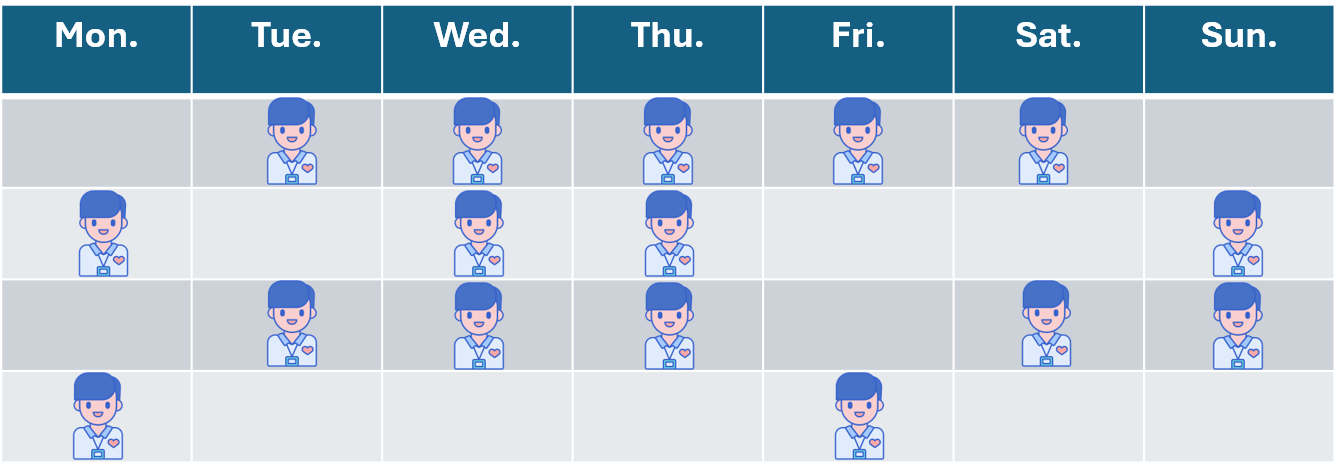

The following schedule shows a plan where Paul works for 9 days and, therefore, the assignment deviates a total of 3 days from his contract specifications.

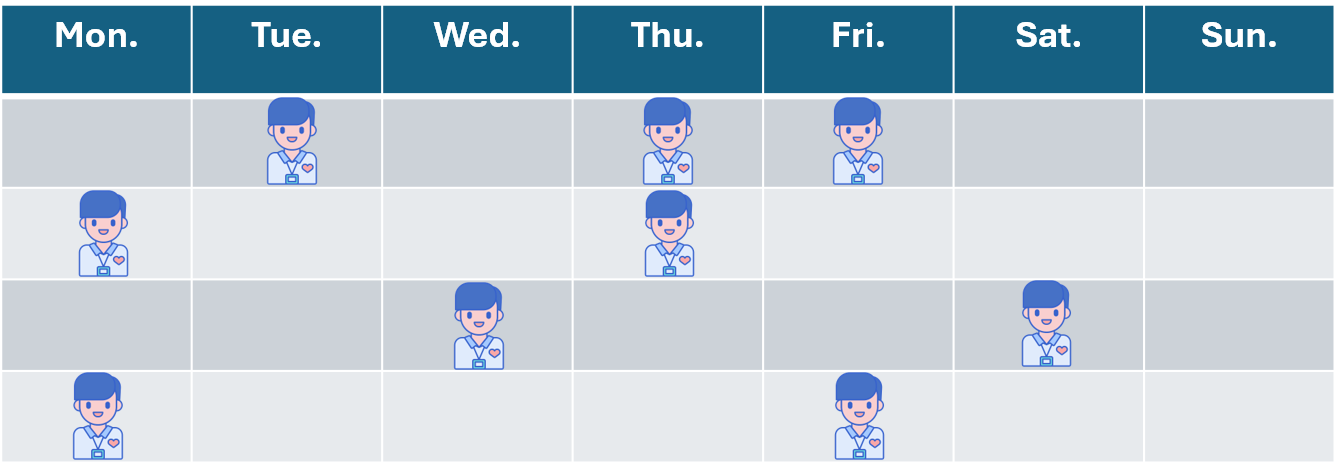

Finally, in the next assignment, Paul works for 20 days during the planning period. This schedule deviates in 2 days from his work contract. From the two latter scenarios, the hospital prefers the last one since it deviates less days.




### Minimum and maximum number of consecutive days working

By contract, when Paul retakes work from his days off, he should ideally work between 2 and 3 consecutive days. The following 4-week assignment shows the schedule for Paul in the coming weeks.

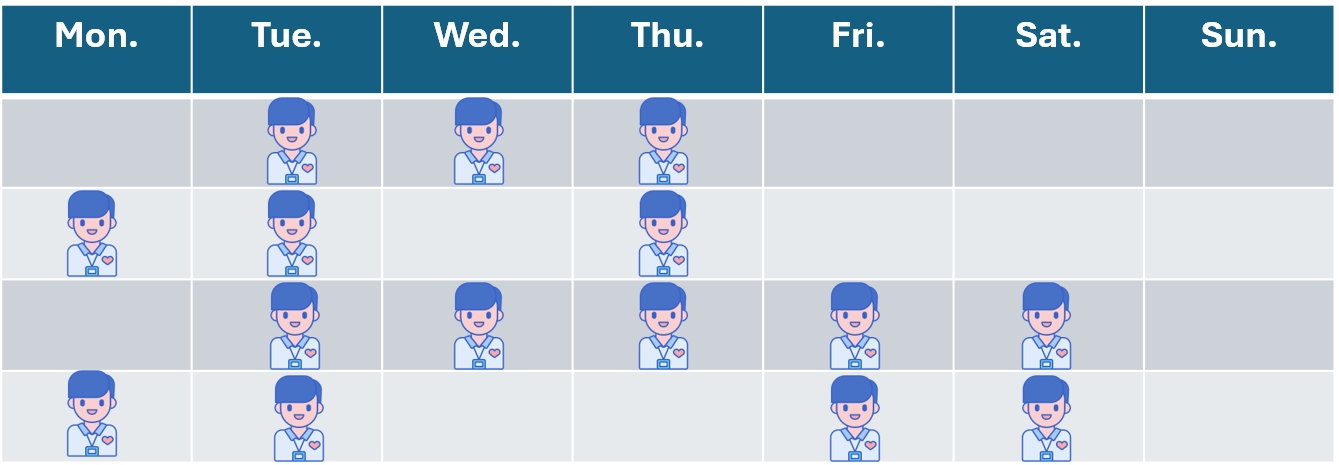

In the first week, Paul retakes work and works for exactly 3 consecutive days, complying with his contract specifications. After resting for several days, Paul retakes work at the start of the second week and works for 2 consecutive days, fulfilling again his contract. Then, he has one day off and works a single day. This deviates in 1 day from the ideal scenario. The third week, Paul retakes work and he is assigned 5 days in a row, deviating 2 consecutive days from its contract. The fourth week, Paul works two times for 2 consecutive days, incurring in no deviation from its contract. As a consequence, in this schedule, Paul deviates a total of 3 days from this contract specification.

### Minimum and maximum number of consecutive free days

Another contract clause specifies that, when Paul rests, he should take between 1 and 2 consecutive days off. Let us analyze his schedule for the next 4 weeks.

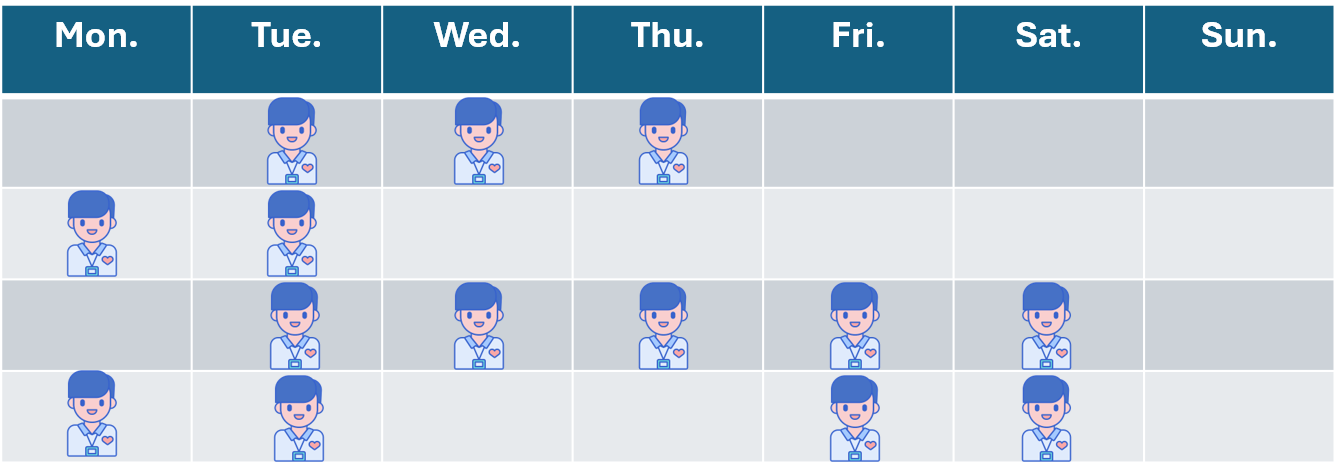

During the first week, he starts by taking one day off. Then, after working for 3 consecutive days, he takes 3 consecutive days off. This rest period deviates in 1 day from his contract clause. The next week, he takes four consecutive days off, deviating in 2 days from his contract clause. During the third and fourth week there are no contract deviations. In total, this schedule deviates 3 days from this contract clause.

### Complete weekends

Ideally, when Paul works a weekend, he should do both Saturday and Sunday. The next schedule shows several deviations from this legal clause.

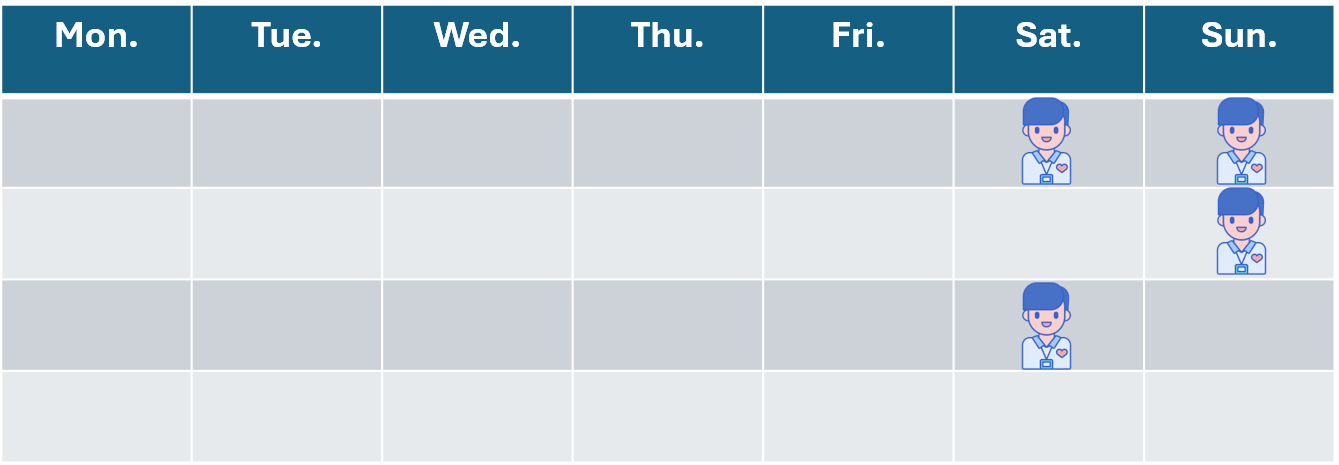

The first weekend, Paul works for both days. The next two weeks, Paul works on Sunday and Saturday respectively. This means, that both weekends violate his contract clause. Please, realize that the fourth week does not violate the contract clause since it does not force Paul to work for every weekend. Thus, in total, this schedule deviates a total of 2 weekends from the ideal scenario.

### Same shift during the weekend

Another contract clause determines whether or not, the worker should do exactly the same shift the two days working in a weekend. Let us assume that Paul has this clause in his contract and let us analyze the following schedule.

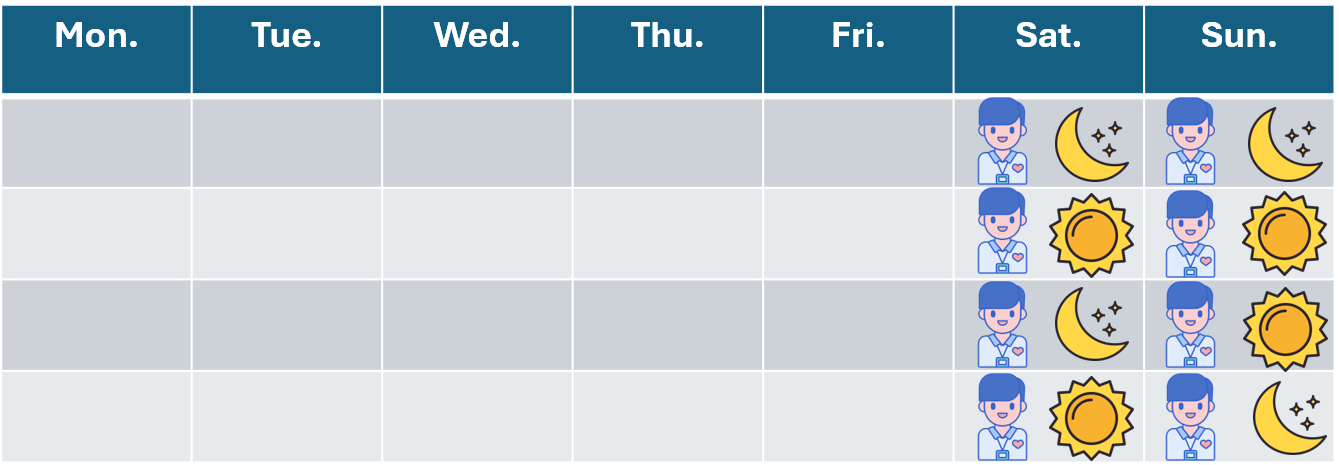

During the first two weekends, Paul does the same shift for Saturday and Sunday. The first week he is assigned to the night shift and the second week he is assigned to the morning shift. Then, this schedule deviates 2 weekends from the ideal scenarios, since the two following weeks Paul does different shifts in Saturday and Sunday.

### Unwanted patterns

An unwanted pattern (there may be several) specifies a sequence of shift assignments that should be avoided for the same worker. For instance, let us assume that the hospital has a total of three shifts: early, morning, and night.

Paul has specified two unwanted patterns: night-early and night-night-night. The following schedule presents several problematic assignments.

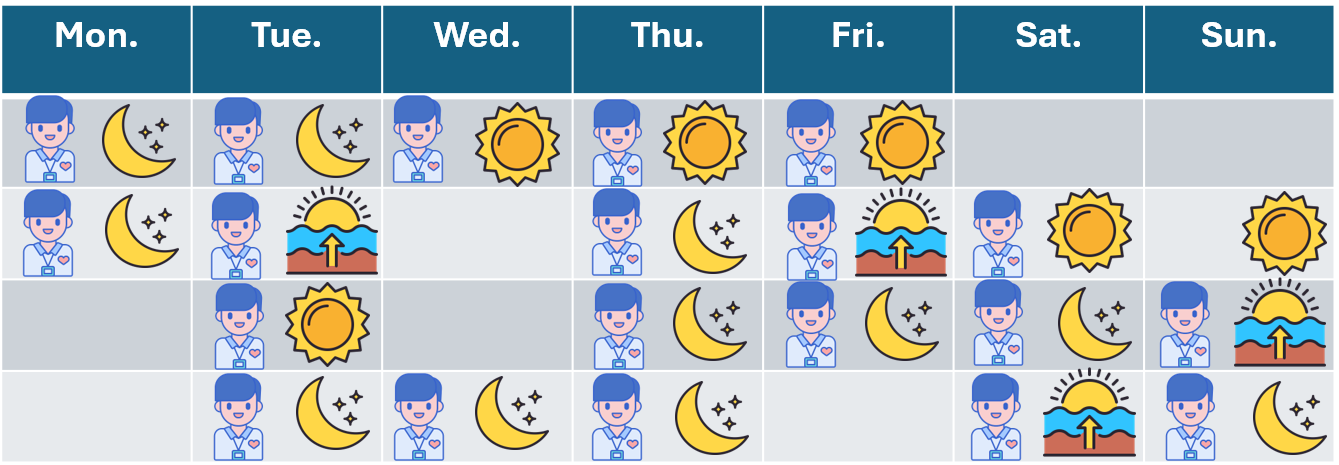

In the first week there are no unwanted patterns. Then, the second week we can find several unwanted patterns. As you can realize, Paul does the night shift and the following day the early shift 2 times. The third week we can find 2 unwanted patterns, since Paul does three night shifts in a row and he also does 1 night shift followed by an early shift. Finally, the last week he does again 3 night shifts in a row. Please, realize that the last two working days do not represent any unwanted pattern since the pattern specifies that a night shift is followed by an early shift and not the other way around. Therefore, in this schedule we can find a total of 5 unwanted patterns.



### Days off

A day off represents a day that the worker has requested vacation. Ideally, these preferences should be respected in the proposed assignment. Let us assume that Paul has requested the following days off (marked in red).

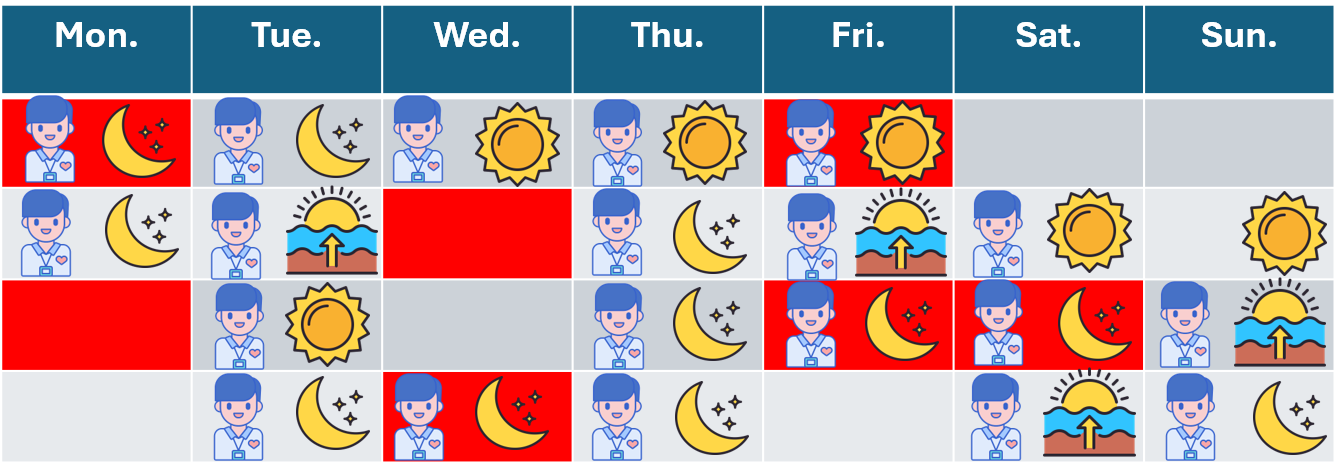

As one may observe, Paul is assigned 5 of his requested days off and he is not assigned 2 of them.

### Shift off

A shift off is a special request from the worker to avoid being assigned to a particular shift. Let us assume that the red days Paul has requested not to be assigned to the morning shift, and the blue days Paul has requested not to be assigned to the night shift.

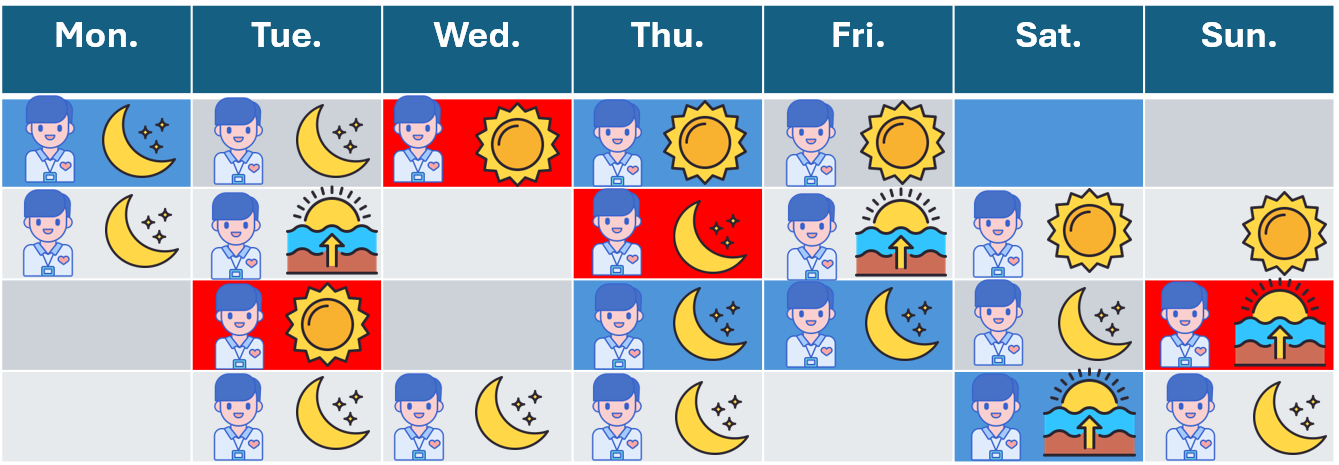

Paul, having requested not to be assigned for the morning shift for 4 days, he is assigned a total of 2 days. Then, having request not to be assigned for the night shift for 6 days, he is assigned a total of 3 days. Thus, this schedule deviates a total of 5 days from the ideal scenario.

### Objective

The main objective for the schedule is to find a **feasible schedule** that minimizes the total amount of deviation from the ideal schedule.

Let us assume that Paul:
- Should work between 12 and 16 days for the planning period.
- Should work between 2 and 3 consecutive days.
- Should rest between 1 and 2 consecutive days.
- If assigned during a weekend, he should be assigned the whole weekend and do the same shift on both days.
- Wants to avoid 3 consecutive night shifts and then a night shift followed by an early shift.
- Has requested the green days as days off.
- Has requested to avoid being assigned to the night shift on the blue days, and has requested to avoid being assigned to the morning shift on the red days.

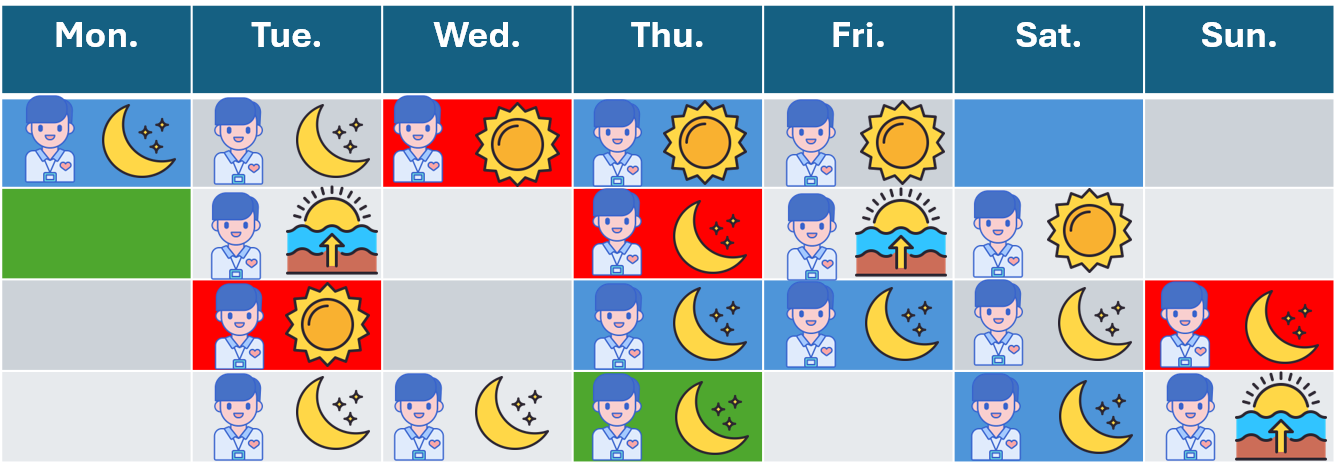

Let us see how Paul's schedule deviates from these clauses and preferences:

- Works 4 extra days with respect to his maximum assignment.
- Works 1 extra consecutive day during the first week, needs 1 extra consecutive day during the second week, and needs 1 extra day and lacks 1 extra day during the third week. Thus, in total his schedule deviates in 4 days.
- Rests 1 extra day between the first and second week.
- Is not assigned a complete weekend for 1 weekend.
- Does not do the same shift for Saturday and Sunday for 1 weekend.
- Does three nights in a row 3 times.
- Works a night shift followed by an early shift a total of 2 times.
- Is assigned to work on 1 requested day off.
- Is assigned to work on 4 night shifts when he requested not to be assigned to the night shift.
- Is assigned to work on 2 morning shifts when he requested not to be assigned to the morning shift.

Therefore, the total amount of deviation stemming from Paul's schedule is $4+4+1+1+1+3+2+1+4+2=23$.

To this deviation, we would need to add up any deviation stemming from other workers' assignments and also the deviation stemming from the established daily demand per shift.

# Project objectives and phases

The objective of the project is: **To program a metaheuristic and a MILP mathematical model that is able to find optimal or near-optimal solutions for the given problem**. The project consists of the following phases:


1.   Design of one or several metaheuristics and MILP models for the problem.
2.   Implementation of one or several metaheuristics and MILP models.
3.   Optimization of the hyperparameters of the metaheuristic and/or MILP models to find the best implementation.
4.   Project report.
5.   Submission of your best metaheuristic and mathematical model to a tournament among your classmates.


## Data available

Each problem instance is described by means of a JSON object that contains all of the relevant information. More specifically, each JSON object contains:

|Attribute|Description|Data type|
| --- | --- | --- |
| *number_of_days* | For how many days the schedule should be produced. Days start from index 0 and go up to n-1| Integer |
| *skills* | A list of strings that contains the skills that are considered in the planning | List of strings |
| *shifts* | A list of shift objects. To be described later | List of objects |
| *nurses* | A list of nurse objects. To be described later | List of objects |

For instance, the following code snippet contains an example of a problem instance object. Please, realize that the list of shifts and nurses are not specified for simplicity.

```JSON
{
  "number_of_days": 28,
  "skills": [ "Nurse", "HeadNurse" ],
  "shifts": [ ... ],
  "nurses": [ ... ]
}
```

In this problem, we need to plan for 28 days for two types of roles (i.e., Nurse and Head Nurse).

Each shift object contains information about one of the shifts that needs to be covered. Particularly, each object contains the following information:

|Attribute|Description|Data type|
| --- | --- | --- |
| *shift_id* | The identifier of the shift | Text |
| *needed_skill* | What skill is needed for this shift. Matches one of the aforementioned skills | Text |
| *demand* | Contains the preferred number of nurses assigned to this shift for each of the days of the planning | List of Integers |

For instance, the following code snippet contains an example of a shift object.

```JSON
{
  "shift_id": "E",
  "needed_skill": "Nurse",
  "demand": [8, 8, 8, 8, 8, 6, 6, ..., 8, 8, 8, 8, 8, 6, 6]
}
```

In the previous example, we define a nurse shift named *E* (stems from early) that needs 8 nurses during the week days and 6 nurses in the weekends.

Each nurse object contains information about one of the nurses available for the scheduling. Each of these objects contains the following information:

|Attribute|Description|Data type|
| --- | --- | --- |
| *nurse_id* | The nurse identifier | Integer (starts from zero) |
| *skills* | What skills/roles can be played by this staff member | List of strings |
| *days_off_requests* | A list with the days that have been requested as days off by this nurse | List of integers |
| *shift_off_requests* | A list of dictionaries. Each contains combinations of days and shifts to be avoided for assignment | List of dictionaries |
| *max_assignments* | Maximum number of days to be assigned | Integer |
| *min_assignments* | Minimum number of days to be assigned | Integer |
| *min_consecutive_days* | Minimum number of consecutive days to work | Integer |
| *max_consecutive_days* | Maximum number of consecutive days to work | Integer |
| *min_consecutive_free_days* | Minimum number of consecutive free days to have | Integer |
| *max_consecutive_free_days* | Maximum number of consecutive free days to have | Integer |
| *complete_weekends* | If both Saturday and Sunday should be assigned when working on a weekends | Boolean |
| *same_shift_weekend* | If the same shift should be assigned when working on Saturday and Sunday | Boolean |
| *unwanted_patterns* | Sequences of shift assignments to be avoided | List of strings |

The following is an example of a nurse object:

```JSON
{
  "nurse_id": 0,
  "skills": [ "Nurse", "HeadNurse"],
  "days_off_requests": [0, 5, 7, 8, 11, 13, 16, 17, 18, 21],
  "shift_off_requests": [
                {"day": 4, "shift_type": "E"},
                {"day": 7, "shift_type": "L"},
                {"day": 10, "shift_type": "D"},
                {"day": 10, "shift_type": "DH"},
                {"day": 24, "shift_type": "DH"}
            ],
  "max_assignments": 16,
  "min_assignments": 6,
  "min_consecutive_days": 1,
  "max_consecutive_days": 7,
  "max_consecutive_free_days": 5,
  "min_consecutive_free_days": 1,
  "complete_weekends": true,
  "same_shift_weekend": true,
  "unwanted_patterns": [ "L-D", "D-E-D"]
}
```

This nurse, whose identifier is 0, can play both the role of nurse or a head nurse. He/She has requested to rest on several days (i.e., 0, 5, 7, 8, 11, etc.), and does not want to be assigned to some particular shifts in some days (e.g., he/she does not want to be assigned to shift E in day 4). The nurse can work between 6 and 16 days during the planning period and she can work between 1 and 7 consecutive days. When resting, she can rest between 1 and 5 consecutive days. In addition to this, when working on a weekend she has to be assigned to both Saturday and Sunday, and the same shift should be assigned on both days. Finally, the nurse wants to avoid working on the L shift and then working on the D shift the next day. Moreover, she also wants to avoid doing the D shift, then the E shift and finally the D shift again.

To test the performance of your proposed optimization algorithms and models, as well as to determine the best configuration, 7 problem instances with different input data are attached. Each of these instances describes a problem. The instances can be found at [following address](https://gitlab.com/drvicsana/nursescheduling-project/-/blob/main/problem_instances/public_instances.zip).


## Implementation requirements

The **developed code** will be submitted in a *.zip* file that will be uploaded to PoliformaT.

As a general rule, you should implement a file named *metaheuristic.py* and a file named *milp.py* that contain both a metaheuristic and a milp model with the following characteristics:
* The *metaheuristic.py* should contain a Python class, named as *Metaheuristic* that implements the logic of the metaheuristic to be submitted.
* The constructor of the metaheuristic will take two compulsory arguments. First, the path to the file that contains the problem to be solved. The file will have the format indicated at the *Available Data* section. Second, a maximum computation time.
* The constructor can take other optional arguments to configure the algorithm. However, the default values for these parameters should be the best values found in the experimental optimization of the algorithm. This may be useful to reuse code and logic of the metaheuristic.
* The class will implement the method *get_best_solution*, that will return the best solution found up to this point in the metaheuristic (the run may have not finished!). In this case, a list of lists will be returned. The outer list contains as many lists as workers and each list specifies the shift identifier (string) to be assigned to that worker for each of the days of the schedule (we will use "OFF" for unassigned).  **If you do not follow this format, your submission will not participate in the tournament**. Please, note that, internally, you can represent solutions as you see fit. However, the *get_best_solution* is a method that returns the best solution externally and we need a common format to exchange information between your metaheuristic and other code.
* The method *run* will implement the logic of the metaheuristic (i.e., initialization, calculations, looping, etc.).
* The class will implement the *read_problem_instance* method, that will read the information of the problem to be solved. **No precomputations or search are allowed in this method**.

A template for the file *metaheuristic.py* is included as part of the repository of this project. Feel free to add more methods as you need them. Do not modify the basic structure of the methods already described in the template. The *milp.py* template is very similar, but it will automatically create a solver object in the run method and call the Solve method.


You will also submit a file named *experiments_metaheuristic.py* and *experiments_milp.py*. In this file, you will include all the code developed for optimizing the configuration of the metaheuristic and MILP model. This includes the selection of operators as well as relevant hyperparameters and solvers. The experimentation should adhere to the following rules:

* A time limit of 120 seconds will be employed per run of the optimization method. This limit includes reading the instance, precomputations, initialization of the method and its main logic. The project includes a template, named as *tester.py* that shows how the execution of the metaheuristic(following the previous template) can be bounded in time. The code for testing the MILP model would be very similar.
* The metric employed to assess the quality of the optimization algorithm in a single run will be the value of the objective function for the best solution found in that run. In case of a tie, we will employ the computation time. Infeasible solutions will count as solutions with $∞$ value for the objective function.
* Each configuration tested (e.g., specific combination of hyperparameters and operators) should be tested several times. This way, we can estimate the **average** value of the objective function obtained by the optimization algorithm. It is important to test the same configuration several times, as some algorithms have a stochastic behavior.
* When comparing different configurations of a metaheuristic (e.g., a genetic algorithm), it is important that populations or initial solutions are the same. Populations can be different for each run. That is, if I repeat each configuration 50 times, the initial population for each of the 50 runs can be different. However, when comparing two configurations, the population of the $i$-th run should be the same for both.
* Obtained results will be attached and summarized as part of the project report.
* The experiments' code should be executable and replicable.
* To optimize the hyperparameters and configuration of the optimization algorithm you are encouraged to use grid search, random search, or more advanced methods like bayesian optimization. Code should be provided for those.


The templates of the project can be found in the following [repository](https://gitlab.com/drvicsana/nursescheduling-project/).

## Metaheuristic tournament

As mentioned, your best metaheuristic will participate in a tournament where you will face some baseline strategies and the best metaheuristics of the other teams. The main goal of this tournament is determining and awarding the best performing submissions.

In order to participate in the tournament, your submission should comply with the specifications of the template *metaheuristic.py*.

The baselines that will participate in the tournament are:
* A random search procedure that internally represents a solution as a list of lists of strings (tournament format). The metaheuristic randomly generates **feasible** schedules and aims to assign, if possible, the preferred number of nurses per shift and day. The algorithm keeps generating random feasible solution while there is time available and keeps track of the best solution found so far.
* A genetic algorithm that:
  * Internally represents a solution with the tournament format.
  * Generates an initial random population of 30 **feasible** individuals using the same procedure than in random search.
  * Employs binary tournament selection to select 10 individuals of the population as parents.
  * With 70% probability, both parents undergo the crossover operation, using one-point crossover at one of the nurses' schedule. Otherwise they are copied and may undergo mutation.
  * With a 20% probability each solution copied or created by crossover undergoes the mutation operator. This operator randomly changes each gene with a 5% probability.
  * After creating new solution, they are fixed to guarantee that all of the shifts have, if possible, the preferred number of nurses.
  * The top individuals from the population and generated children are used as the next generation.


A question that may arise is how the tournament will be carried out. A set of test instances will be employed for the tournament. Test instances will not be necessarily the same than the ones provided at the repository and they won't be available for testing. This is done to avoid teams overfitting their algorithms to the available instances or making optimizations solely based on the structure of the available instances. Remember, that the goal is designing metaheuristic whose performance is consistent among different instances.

For each combination of test instance and algorithm, a total of 10 executions will be run. Therefore, the total number of executions will be $number\_algorithms \times number\_test\_instances \times 10$. Then, the average fitness and average time will be computed for each combination. The following table shows an example for 3 algorithms and 5 test instances.

|Algorithm|Test instance | Avg. fitness | Avg. time |
| --- | --- | --- | --- |
| alg1 | test01 | 12.45 | 167.5 |
| alg1 | test02 | 562.12 | 179.87 |
| alg1 | test03 | 2444.11 | 179.23 |
| alg1 | test04 | 850.34 | 120.24 |
| alg1 | test05 | 40.15 | 112.3 |
| alg2 | test01 | 24.56 | 180.0 |
| alg2 | test02 | 456.24 | 175.16 |
| alg2 | test03 | 3200.1 | 169.83 |
| alg2 | test04 | 700.12 | 170.24 |
| alg2 | test05 | 35.23 | 115.67 |
| alg3 | test01 | 34.45 | 162.9 |
| alg3 | test02 | 500.88 | 177.17 |
| alg3 | test03 | 4000.25 | 179.13 |
| alg3 | test04 | 400.15 | 128.24 |
| alg3 | test05 | 67.6 | 146.23 |



As problem instances have different sizes, averaging the fitness of all instances would not be fair and could potentially drag comparison. To avoid this problem, we follow the recommendations of Derrac, García, Molina and Herrera (2011) for multiproblem analysis. Thus we calculate the rank of each algorithm for each problem instance using the fitness as a first criteria and time in the case of ties. Assuming a minimization problem, the resulting table used for the comparison would be:

|Test instance|Rank alg1 | Rank alg2 | Rank alg3 |
| --- | --- | --- | --- |
|test01| 1 | 2 | 3 |
|test02| 2 | 1 | 3 |
|test03| 1 | 2 | 3 |
|test04| 3 | 1 | 2 |
|test05| 2 | 1 | 3 |

Then, the average rank for each algorithm is calculated:

| Algorithm | Average rank |
| --- | --- |
| alg2 | 1.4 |
| alg1 | 1.8 |
| alg3 | 2.8 |

The best performing algorithm in this case would be alg2, followed by alg1 and alg3.

Some frequently asked questions that we have received from previous years:


* **Can my metaheuristic carry out some precalculations in the class constructor?** No. All the major computation should be carried out in the *run* method. Otherwise, your submission will not participate in the tournament.
* **What Python version will be employed in the tournament?** 3.10
* **Can my metaheuristic use external libraries or packages?** Only those packages that are available by default on Python (no pip install required. https://docs.python.org/3/library/), Numpy, and Scikit. In addition to this, you can also use the ORTools' pywraplp API to build MILP models. The only condition is that MILP is not the main and single optimizer. You can create **hybrid methods** that combine the power of both heuristic and exam methods.
* **Can my metaheuristic use multithread programming?** No, all the algorithm should be executed in a single thread and the execution should be sequential. That is, no parallelism is allowed.
* **Can my metaheuristic use all the RAM memory that I want?** No, a maximum of 8GB of RAM is allowed for the execution of the genetic algorithm.
* **Can my metaheuristic reuse or store information between executions of the metaheuristic?** No, all runs should start from scratch with no information from previous runs.
* **Can my metaheuristic write data or information to the hard-disk?** No, all data should be present in the RAM memory of the program.


## References

*Derrac, J., García, S., Molina, D., & Herrera, F. (2011). A practical tutorial on the use of nonparametric statistical tests as a methodology for comparing evolutionary and swarm intelligence algorithms. Swarm and Evolutionary Computation, 3-18.*


## MILP tournament

Your best MILP model will compete in a tournament where you will face a single baseline strategy and the best MILP models of the other teams. The main goal of this tournament is determining and awarding the best performing submissions.

In order to participate in the tournament, your submission should comply with the specifications of the template *milp.py*.

The baseline that will participate in the tournament is a MILP model that finds **feasible** schedules and aims to minimize deviations from the preferred number of nurses per day and shift.

The tournament will be carried out in the same way than in the case of the metaheuristic tournament. Some frequently asked questions about this tournament:

* The MILP model should be built using **ORTools' pywraplp module**. The solvers that can be employed are the ones **freely available** through ORTools' installation.
* **Can my MILP model carry out some precalculations in the class constructor?** No. All the major computation should be carried out in the *run* method. Otherwise, your submission will not participate in the tournament.
* **What Python version will be employed in the tournament?** 3.10
* **Can my MILP model use external libraries or packages?** In this case, all of the decisiones must be made by the mathematical model, leaving the door closed for hybrid methods.
* **Can my MILP model use multithread programming?** No, all the algorithm should be executed in a single thread and the execution should be sequential. That is, no parallelism is allowed.
* **Can my MILP model use all the RAM memory that I want?** No, a maximum of 8GB of RAM is allowed for the execution of the genetic algorithm.
* **Can my MILP model reuse or store information between executions of the metaheuristic?** No, all runs should start from scratch with no information from previous runs.
* **Can my MILP model write data or information to the hard-disk?** No, all data should be present in the RAM memory of the program.

## A note on the use of generative artificial intelligence

As this project is designed to give you the opportunity to work in a real project, we cannot preclude you from using generative artificial intelligence since it is another tool available in the marketplace. You are welcome to use generative AI tools (like ChatGPT, Claude, Gemini, etc.) in this project, but there are some important guidelines to follow:

* Use AI to get ideas, brainstorm, or improve writing (style, clarity, structure).
* Ask AI to explain complex concepts in simpler terms, but make sure you still understand them.
* Use it to test alternatives (e.g.,  pros/cons of a strategy).
* It should support your work, not replace your own critical thinking and decisions.
* You should **actively contribute** to your project and do not solely rely everything on the AI.
* And mode importantly, perhaps the most important tip is that **YOU SHOULD ALWAYS BE IN CONTROL AND FULLY UNDERSTAND WHAT HAS BEEN DONE AND HOW**.

**What You Must Do**

* Be transparent: say clearly if and how you used AI and in what parts. If I suspect that you used generative AI and you did not report it honestly, I reserve the right to fail your project, and propose the case to the academic dishonesty commission.
* Check everything: AI is quite prone to make mistakes, specially when it comes to mathematical reasoning. You are responsible of making sure that the model works correctly as intended. Therefore, you should reason in the report why and how the proposed model aligns with the project requirements and specifications, and why the different components of the model work as a whole. We will be specially strict with modelling mistakes and non-sensical decisions, and they will negatively penalize your marks. This also applies to coding.
* AI can give you ideas about problem and constraint types, but you should further extend research to see whether or not they are feasible ideas.
* Decide critically and add your voice: don't just copy what AI says. You should choose what is useful and adapt it to your own project. Show evidences of the responses given by AIs and why you believe they require adaptation, changes, and your own thinking. Show reflection. Your final work should show your reasoning and decisions, not just AI outputs.
* Be innovative: You should show that your ideas also contributed to the project. The model should incorporate blocks and ideas that come from your own. You should highlight these in the report.

## Project report

An **article** should be submitted in PDF format with a maximum length of **10 pages**, using the IEEE template available at [following link](https://www.ieee.org/content/dam/ieee-org/ieee/web/org/conferences/conference-template-a4.docx). Stick to the format of the template as much as possible. The language of the article shall be **English**. The sections that should appear (as a minimum) in the article are:
* Abstract: This section will describe between 150 and 250 words the genetic algorithm proposal that has been made, as well as the results obtained in the experiments performed.
* Introduction: This section will briefly explain the problem to be solved, the importance of this problem for the organization, and the type of techniques to be used for its resolution. Finally,  how the article is organized in sections will be described.
* A section describing the use of generative artificial intelligence.
* Detailed description of the submitted MILP model. Mathematical optimization models should be described as it has been done in lectures. That is, using both mathematical notation and natural language. Specifically, the following elements should be defined:
    * Decision variables: Their symbol, their description in natural language, as well as the nature (e.g., integer, binary, real) and domain of the variable (e.g., non-negative) must be defined.
    * Constants: In case of using constants or mathematical notation to define some coefficients or input data of the model, these should also be specified. Specifically, the symbol associated to each constant should be specified, as well as an explanation in natural language of the meaning of such constant.
    * Constraints: For each constraint or family of constraints, a name shall be assigned to identify it, an explanation shall be given in natural language of what the constraint is intended to accomplish, and the mathematical definition of the constraint shall be included. If a family of constraints is defined, it is important to define the corresponding subscripts and indicate the range of the subscripts when generating all the constraints of that family.
    * Objective function: The sense of the optimization (minimize or maximize) as well as the definition of the mathematical function to be optimized should be defined. In addition, an explanation in natural language should be included to explain what is calculated with the proposed objective function and how this calculation is carried out.
* Detailed description of the design of the submitted metaheuristic. All the operators and phases should be described and examples/traces provided. Pseudo-code should be included and explained for relevant algorithms. Please, remember that figures can help the understanding of concepts and algorithms.
* Experiments: First you should describe what the objective of the experiments is, and after that describe the set of experiments designed: configurations tested, replications carried out, and comparison strategy. The results shall be reported with appropriate tables and/or graphs.  The conclusions of the experiments shall be supported by statistical significance tests.
* Conclusions: Summarize the problem posed, the algorithm proposed, the experiments carried out, and the conclusions drawn from them. Possible improvements on your model, as well as on the experiments carried out, will also be described.
* References: References used in the article to any external resource that has been cited.

## Project marks

The marks of the project will be calculated by means of the following formula:

$Human\_Agency \times Work\_quality$



### Human agency

The first term, $Human\_Agency$, marked between 0 and 1, represents the capacity of people to maintain autonomy, make meaningful choices, and retain ultimate intellectual and factual control over the processes and outcomes generated by an AI system. A good human agency ensures that humans act as the governing authority rather than passive recipients of machine-driven outputs. In an academic context, Human Agency is defined as a student's intentional, critical, and accountable ownership over the intellectual process and the resulting scholarly work, regardless of the digital or computational tools employed. When generative AI tools are used during research, writing, or problem-solving, human agency represents the boundary between active intellectual leadership and passive automation reliance. It determines whether the AI was directed as a supplementary aid or whether it effectively replaced the student's own cognitive labor.

In a project focused on mathematical modeling and algorithm engineering, Human Agency measures whether you acted as the lead architect and strategist, or simply let the AI write code and equations you don't fully understand. Some core human agency concepts that are evaluated in this project are:


1. Intellectual Vision: You retain complete authority over the core ideas, research questions, hypothesis, and argumentative direction. You may use AI to explore options or test ideas, but the overarching thesis, structure, and conceptual framework originate from your original thinking.
2. Mathematical Architecture: You retain complete ownership over translating the real-world problem statement into a rigorous mathematical model. You define the decision variables, objective function, and constraints based on domain knowledge. If an AI suggests a formulation, you verify that every constraint set correctly captures the problem physics and logic rather than accepting an oversimplified or incorrect set of equations. In addition to this, you fully understand how the model works and why it works.
2. Algorithmic Strategy: You make the high-level design decisions regarding how the metaheuristic explores and exploits the solution space. For instance, you choose the metaheuristic framework based on your own hypothesis and knowledge (e.g., Genetic Algorithm, Simulated Annealing, Tabu Search) and explicitly design its core operators, such as solution representations, neighborhood structures, repair mechanisms, and cooling schedules. You do not rely on AI to blindly pick hyperparameters or search strategies. You understand the core logic behind every single algorithmic design.
3. Verification & Diagnostic Auditing. You actively test, stress-test, and debug both the mathematical formulation and the algorithm implementation. When a solver returns INFEASIBLE or a metaheuristic gets stuck in local optima, you perform diagnostic analysis (e.g., checking conflicting constraints, testing on toy instances, tuning parameters). You do not copy-paste error logs into AI to blindly apply code patches without understanding why the bug occurred.
4. Code & Result Ownership. You take full responsibility for the validity of the code, computational performance, and insights derived from the models. You understand every line of Python code in your submission. You can explain computational trade-offs and why decisions were made.
5. Scholarly accountability. You accept full intellectual, ethical, and academic responsibility for every claim, source, and conclusion within the final submission.

Next, you can find examples of scenarios with high a low human agency.

| Project Stage | High Human Agency (Active Architect) | Low Human Agency (Passive Copy-Paster) |
| --- | --- | --- |
| **Role of AI** | Thought partner, feedback mechanism, or drafting assistant. | Primary author, reasoning engine, and content provider. |
| **Prompting Approach** | Specific, contextual, iterative, and constrained by student rules. | One-shot, broad prompts (*"Write an essay about..."*). |
| **MILP Formulation** | Writes or carefully verifies model components and their logic | Prompts AI with the problem statement and pastes the generated equations without checking. |
| **Metaheuristic Design** | Customizes solution representations and neighborhood operators specifically tailored to the problem's topology. | Asks AI for "a Genetic Algorithm in Python" and uses generic crossover/mutation operators that produce illegal or low-quality solutions. |
| **Code Understanding** | Can explain any line of model setup, constraint addition, or heuristic loop during a defense or code review. | Unable to explain specific algorithmic steps, Gurobi parameters, or matrix index structures used in the submitted code. |
| **Verification** | All claims, facts, and references cross-checked with academic sources. | AI output pasted directly into submission without fact-checking. |
| **Voice & Logic** | Clear, personal academic voice with cohesive, original logic. | Generic, formulaic prose ("AI voice") with shallow reasoning. |
| **Ownership** | *"I used AI to help refine my argument for X."* | *"The AI gave me this response for assignment task Y."* |


Human Agency will not be evaluated merely by reading your report or inspecting your code repository. Instead, it will be assessed directly through a **live Team Project Defense and Agency Interview** (~30-40 minutes total).

The purpose of this session is not to penalize you for using Generative AI or assessing the techincal quality of your work, but to verify that **your team was the true architect, engineer, and decision-maker** behind the submitted work. The defense will be divided into two phases:



#### Phase 1: Executive Briefing (10 Minutes)

Your team will deliver a concise presentation focusing **only** on high-level architecture and key takeaways:

* **The Problem & MILP Model:** Key decision variables, critical non-obvious constraints, and model size.
* **The Metaheuristic:** The chosen framework, core operators (representation, neighborhood, repair), and why they fit this problem structure.
* **Experimental desing:** How you carried out experiments.


#### Phase 2: Agency & Technical Probe Interview (20-30 Minutes)

The evaluation committee will engage your team in an interactive, deep-dive interview. Questions may be directed to **any individual team member** at any time to verify collective ownership and technical comprehension across the entire project.

#### Required Interview Setup (Have Open BEFORE Entering)

Significant time wasted navigating directories or searching for files will directly reduce your interview score. Your team screen must be ready with:

* **IDE / Code Editor:** Open to the project repository with code clean, runnable, and well-commented.
* **Live Working Environment:** ORTools logs, test scripts, and execution outputs ready to run or inspect.
* **Project Report & LaTeX Source:** Open for quick reference to equations, constraint indices, and figures.
* **AI Prompt History & Transparency Logs:** Complete records of conversation threads, prompts, and raw AI outputs used during development.

#### What You Are Expected to Demonstrate

During the interview, the committee will evaluate your human agency based on these non-negotiable expectations:

1. **Individual & Collective Mastery:** Every team member, regardless of their primary role during development, must thoroughly understand the MILP formulation, the algorithm logic, and every key component of the Python code. *"I only worked on the report"* or *"Person X wrote that code"* is **not** an acceptable answer.
2. **Architectural Justification:** For instance, you must be able to defend *why* specific choices were made (e.g., choice of metaheuristic, neighborhood design, constraint structuring, penalty terms) rather than just describing *what* was done.
3. **Critical AI Auditing & Honesty:** Be completely transparent about where AI was used, where it failed, how you caught its errors, and how you refined its outputs.



#### Demystifying the Defense: What This Interview Is (and Isn't)

If you have never faced an oral defense before, this evaluation format might sound intimidating. **Please don't panic.** We are not trying to catch you out, trick you, punish you, or interrogate you.

Think of this session as a **professional engineering design review**, which is the exact type of conversation you will have with senior engineers, project managers, or clients in your future career.

|IT IS NOT| IT IS|
| --- | --- |
| A trap to catch you using AI | A conversation about your work |
| A test of perfect memorization | A check on your understanding |
| A punishment for code errors | An opportunity to show mastery |

A quick reference about the defense's do's and don'ts:

| DO NOT | DO |
| --- | --- |
| Waste time looking for files, code snippets, or prompt logs. | Have all files, IDE tabs, and prompt logs open and organized on screen **before** the session starts. |
| Defer technical questions about code or equations to a single "lead programmer." | Ensure every team member can explain any line of code or math constraint when called upon. |
| Claim you wrote 100% of the code if you used AI to draft functions or debug syntax. | Proudly disclose AI assistance while proving you fully comprehend, tested, and own the code. |
| Justify a design decision by saying *"The AI suggested it"* or *"It worked best."* | Explain the underlying mathematical logic, trade-offs, and alternative approaches you tested. |

When thinking about a project defense, there are some false myths that may come to your mind. Next, you have a compilation of some of those.

* **Myth:** *"If I used AI to help write code, I will be penalized."*
* **Reality:** **No.** Using AI is explicitly allowed! We only care whether you **understand** what the code does, why it is there, and that you verified its correctness.


* **Myth:** *"I have to memorize every single line of code and math formula."*
* **Reality:** **No.** You will have your report and code open right in front of you on your screen! You don't need to memorize equations; you just need to be able to look at your own work and explain the logic behind it.


* **Myth:** *"If I make a small mistake or blank on a question, it's over."*
* **Reality:** **No.** It is okay to take a breath, look at your code, or discuss with your team for a moment before answering. We want to see how you think, not how fast you fire off answers. Of course, time should not be wasted idle.


#### Human agency: assessment rubric

| **Dimension** | **85-100%** | **70-85%** | **50-70%** | **Below 50%** |
| --- | --- | --- | --- | --- |
| **1. Code & Math Comprehension** (35%) <br>*(35% Weight)* | Every team member fluently explains any line of code,<br> index set, or constraint.<br> <br>Seamlessly navigates IDE and equations without hesitation.<br><br>Collective ownership across all parts. |  Most members understand<br> the code and math well.<br><br> Minor hesitations on<br>edge-cases<br><br> Work is slightly siloed,<br> but core concepts are shared. |  Work is heavily siloed;<br> only a few team members understands<br> the code/math.<br> <br>Others struggle to<br> explain core variables or logic<br> when questioned directly. |  Team cannot explain basic<br> sections of their own code<br> or constraints.<br><br> Defers entirely to a<br> single member or admits they<br> do not know how the<br>model functions. |
| **2. Architectural Justification**<br><br>*(35% Weight)* |  Articulates clear,<br> domain-specific engineering reasons<br> for all MILP formulations and metaheuristic operators.<br><br>Thoroughly discusses trade-offs<br> and alternative designs. | Explains major design<br> choices and operator selections logically.<br><br>Some parameter choices<br> lack deep empirical grounding, but overall<br> intent is sound. | Justifies choices vaguely<br> (*"it worked best"* or *"seemed standard"*).<br><br>Operators are generic rather than tailored;<br> trade-offs are poorly<br> understood. | Relies entirely on AI<br> defaults without critical<br> adaptation.<br><br>Unable to explain why<br> specific formulations or<br> metaheuristic strategies<br> were chosen. |
| **3. AI Transparency & Critical Auditing**<br><br>*(30% Weight)* | Completely transparent<br> prompt records and logs.<br><br>Actively identifies<br> where AI generated flawed, inefficient,<br> or invalid logic and demonstrates<br> precise human corrections. | Discloses AI usage<br> openly and provides basic<br> prompt histories.<br><br>Catches obvious AI errors,<br> though a few minor generic<br> structures slipped through<br> unedited. | Provides minimal or<br> incomplete prompt documentation.<br><br>Uncritically accepted<br> a significant amount<br> of AI output with little to<br> no modification. | Fails to disclose AI<br> usage or attempts to<br> hide it.<br><br>Uncritically pastes raw AI<br> code and equations without<br> verification, error checking,<br> or structural ownership. |




### Work quality

Work quality refers to the level of adequacy of the submitted project. These are the classic marks between 0 and 10 that evaluate how the submitted project reflects mastery of the courses' contents.

Next, we attach the assessment rubric for the project. It should be highlighted that the rubric is **approximate**, as it is **IMPOSSIBLE** to identify all prospective scenarios and cases in an open project beforehand.

| Aspect                                       | <50%                                                                                                                                                                                      | 50-69%                                                                                                                                                                                                                  | 70-89%                                                                                                                                                                                                                        | 90-100%                                                                                                                                                                                               |
|-----------------------------------------------|-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| Style, organization and clarity<br>(1 mark)  | The document is not<br> organized in the proposed sections<br><br><br>There is no coherence in<br> ideas and explanations<br><br>References are not present. | There is a certain coherence<br> in ideas and explanations<br><br><br><br>Missing sections<br> or inadequate organization               | There is a certain coherence<br> in ideas and explanation <br><br><br>No missing sections<br><br> Adequate use of figures and tables                        | Ideas and explanations<br> are coherent<br><br>No missing sections <br><br> Adequate use of figures and tables        |
| Metaheuristic and MILP design and<br> implementation <br> (2 marks)                 | Non working implementation<br>  no merit <br> or plagiarized                                                                              | Basic design<br><br>Basic description | Basic design<br><br>Detailed description | Original design<br><br>Detailed description <br><br> Documented code                   |
| MILP Tournament  (2.5 marks) | Improves <br> baselines  | Q4 ranking | Q3 and Q2 ranking | Q1 ranking |
| Metaheuristic Tournament  (2.5 marks) | Improves <br> baselines  | Q4 ranking | Q3 and Q2 ranking | Q1 ranking |
| Experiments <br> (2 marks) | No experiments, no merit,<br> or non-functional | Provided functional code for<br>experiments | Provided functional code for<br>experiments<br><br> Experimental results explained in report | Provided functional code for<br>experiments<br><br> Experimental results explained in report <br><br>Correct methodology for analysis |